In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, accuracy_score)
from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedGroupKFold

DATA_PATH = "american_bankruptcy.csv"   
RANDOM_STATE = 42

In [2]:
df = pd.read_csv(DATA_PATH)
column_mapping = {
    "X1": "Current Assets", "X2": "Cost of Goods Sold", "X3": "Depreciation & Amortization",
    "X4": "EBITDA", "X5": "Inventory", "X6": "Net Income", "X7": "Total Receivables",
    "X8": "Market Value", "X9": "Net Sales", "X10": "Total Assets", "X11": "Total Long-term Debt",
    "X12": "EBIT", "X13": "Gross Profit", "X14": "Total Current Liabilities",
    "X15": "Retained Earnings", "X16": "Total Revenue", "X17": "Total Liabilities",
    "X18": "Total Operating Expenses",
}
df = df.rename(columns=column_mapping)

equity = df["Total Assets"] - df["Total Liabilities"]
df["Return on Assets (%)"]    = df["Net Income"] / df["Total Assets"] * 100
df["Return on Equity (%)"]    = df["Net Income"] / equity * 100
df["Gross Profit Margin (%)"] = df["Gross Profit"] / df["Total Revenue"] * 100
df["Operating Margin (%)"]    = df["EBIT"] / df["Total Revenue"] * 100
df["Current Ratio"]           = df["Current Assets"] / df["Total Current Liabilities"]
df["Debt to Equity Ratio"]    = df["Total Liabilities"] / equity
df["Leverage_Ratio"]          = df["Total Liabilities"] / equity   # NOTE: identical to Debt to Equity
df["Receivables_to_Sales"]    = df["Total Receivables"] / df["Net Sales"]
df["OpEx_to_EBITDA"]          = df["Total Operating Expenses"] / df["EBITDA"].replace(0, np.nan)
df["High_Insolvency_Risk"]    = (df["Leverage_Ratio"] > 2.0) & (df["Current Ratio"] < 1.0)
df["Trade_Credit_Warning"]    = df["Receivables_to_Sales"] > 0.30

feature_cols = [
    "Return on Assets (%)", "Return on Equity (%)", "Gross Profit Margin (%)",
    "Operating Margin (%)", "Current Ratio", "Debt to Equity Ratio", "Leverage_Ratio",
    "Receivables_to_Sales", "OpEx_to_EBITDA", "High_Insolvency_Risk", "Trade_Credit_Warning",
]
df[feature_cols] = df[feature_cols].replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=feature_cols).copy()

In [3]:
labels_per_firm = df.groupby("company_name")["status_label"].nunique()
print("Firms whose label changes over time:", (labels_per_firm > 1).sum(), "of", len(labels_per_firm))
print("-> every year of a failed firm is labelled 'failed'\n")

df["y_orig"] = (df["status_label"] == "failed").astype(int)
last_year = df.groupby("company_name")["year"].transform("max")
df["y_new"] = ((df["status_label"] == "failed") & (df["year"] >= last_year - 1)).astype(int)

print(f"Usable rows: {len(df):,}   Firms: {df['company_name'].nunique():,}")
print(f"Failed firms: {df.loc[df.y_orig == 1, 'company_name'].nunique()}")
print(f"Original label positives: {df.y_orig.sum():,} ({df.y_orig.mean():.1%})")
print(f"Corrected label positives: {df.y_new.sum():,} ({df.y_new.mean():.1%})")

Firms whose label changes over time: 0 of 8971
-> every year of a failed firm is labelled 'failed'

Usable rows: 78,677   Firms: 8,971
Failed firms: 609
Original label positives: 5,219 (6.6%)
Corrected label positives: 1,203 (1.5%)


In [4]:
def make_rf():
    return RandomForestClassifier(n_estimators=200, max_depth=10,
                                  class_weight="balanced_subsample",
                                  random_state=RANDOM_STATE, n_jobs=-1)

def evaluate(y_true, prob, threshold):
    y_pred = (prob >= threshold).astype(int)
    y_true = np.asarray(y_true)
    return {
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
        "Base rate": y_true.mean(),
        "Threshold": threshold,
        "Recall": recall_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "F1 (failure)": f1_score(y_true, y_pred),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Healthy flagged": y_pred[y_true == 0].mean(),
        "Test rows": len(y_true),
        "Test failures": int(y_true.sum()),
    }

X = df[feature_cols].astype(float)
groups = df["company_name"]
results = {}

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X, df["y_orig"], test_size=0.2,
                                          random_state=RANDOM_STATE, stratify=df["y_orig"])
model_A = make_rf().fit(X_tr, y_tr)
results["A: row split, original label"] = evaluate(y_te, model_A.predict_proba(X_te)[:, 1], 0.40)

In [6]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, df["y_orig"], groups))
assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))  # no firm in both sets
print("Train firms:", groups.iloc[train_idx].nunique(), " Test firms:", groups.iloc[test_idx].nunique())

model_B = make_rf().fit(X.iloc[train_idx], df["y_orig"].iloc[train_idx])
results["B: firm split, original label"] = evaluate(
    df["y_orig"].iloc[test_idx], model_B.predict_proba(X.iloc[test_idx])[:, 1], 0.40)

Train firms: 7176  Test firms: 1795


In [7]:
y = df["y_new"]
X_train, y_train, g_train = X.iloc[train_idx], y.iloc[train_idx], groups.iloc[train_idx]
X_test,  y_test           = X.iloc[test_idx],  y.iloc[test_idx]

# Out-of-fold training predictions -> threshold that reaches 70% recall
oof = np.zeros(len(X_train))
sgk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for a, b in sgk.split(X_train, y_train, g_train):
    oof[b] = make_rf().fit(X_train.iloc[a], y_train.iloc[a]).predict_proba(X_train.iloc[b])[:, 1]
threshold = np.quantile(oof[y_train.values == 1], 0.30)
print(f"Threshold chosen on training data (70% recall): {threshold:.3f}")

model_C = make_rf().fit(X_train, y_train)
prob_C = model_C.predict_proba(X_test)[:, 1]
results["C: firm split, corrected label"] = evaluate(y_test, prob_C, threshold)

Threshold chosen on training data (70% recall): 0.283


In [8]:
res = pd.DataFrame(results).T
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
res

,ROC-AUC,PR-AUC,Base rate,Threshold,Recall,Precision,F1 (failure),Accuracy,Healthy flagged,Test rows,Test failures
"A: row split, original label",0.718,0.150,0.066,0.400,0.695,0.117,0.201,0.633,0.371,15736.000,1044.000
"B: firm split, original label",0.672,0.141,0.075,0.400,0.632,0.120,0.202,0.626,0.374,15694.000,1177.000
"C: firm split, corrected label",0.816,0.077,0.017,0.283,0.759,0.050,0.095,0.746,0.254,15694.000,274.000


In [9]:
aucs, praucs = [], []
for a, b in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X, y, groups):
    p = make_rf().fit(X.iloc[a], y.iloc[a]).predict_proba(X.iloc[b])[:, 1]
    aucs.append(roc_auc_score(y.iloc[b], p)); praucs.append(average_precision_score(y.iloc[b], p))
print(f"ROC-AUC: {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")
print(f"PR-AUC:  {np.mean(praucs):.3f} ± {np.std(praucs):.3f}")

ROC-AUC: 0.802 ± 0.007
PR-AUC:  0.064 ± 0.009


In [10]:
order = np.argsort(-prob_C); yv = y_test.values
rows = []
for q in [0.05, 0.10, 0.20]:
    k = int(len(prob_C) * q)
    rows.append({"Top share of firm-years": f"{q:.0%}",
                 "Share of all failures captured": yv[order[:k]].sum() / yv.sum(),
                 "Failure rate in this group": yv[order[:k]].mean()})
print(f"Test base rate: {yv.mean():.3%}")
pd.DataFrame(rows)

Test base rate: 1.746%


,Top share of firm-years,Share of all failures captured,Failure rate in this group
0,5%,0.263,0.092
1,10%,0.442,0.077
2,20%,0.635,0.055


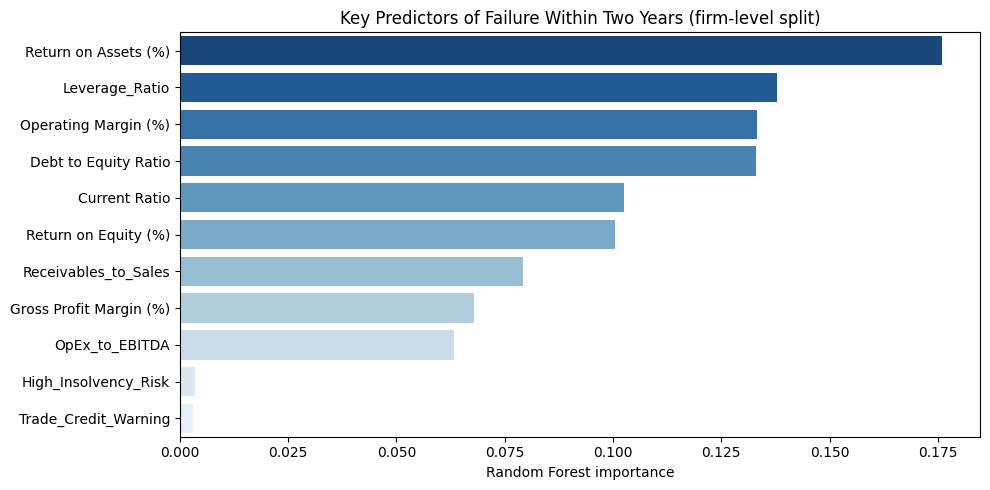

Return on Assets (%)      0.176
Leverage_Ratio            0.138
Operating Margin (%)      0.133
Debt to Equity Ratio      0.133
Current Ratio             0.103
Return on Equity (%)      0.101
Receivables_to_Sales      0.079
Gross Profit Margin (%)   0.068
OpEx_to_EBITDA            0.063
High_Insolvency_Risk      0.003
Trade_Credit_Warning      0.003
dtype: float64

Medians (1 = last two years before failure):
       Return on Assets (%)  Current Ratio  Debt to Equity Ratio
y_new                                                           
0                     1.870          1.910                 0.750
1                   -16.690          1.150                 0.850

Share of firm-years with each rule flag:
       High_Insolvency_Risk  Trade_Credit_Warning
y_new                                            
0                     0.063                 0.094
1                     0.131                 0.101


In [11]:
importances = pd.Series(model_C.feature_importances_, index=feature_cols).sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette="Blues_r", legend=False)
plt.title("Key Predictors of Failure Within Two Years (firm-level split)")
plt.xlabel("Random Forest importance"); plt.ylabel("")
plt.tight_layout(); plt.savefig("key_predictors_firm_split.png", dpi=300, bbox_inches="tight"); plt.show()
print(importances.round(3))

print("\nMedians (1 = last two years before failure):")
print(df.groupby("y_new")[["Return on Assets (%)", "Current Ratio", "Debt to Equity Ratio"]].median().round(2))
print("\nShare of firm-years with each rule flag:")
print(df.groupby("y_new")[["High_Insolvency_Risk", "Trade_Credit_Warning"]].mean().round(3))

In [12]:
roa, de = df["Return on Assets (%)"], df["Debt to Equity Ratio"]
neg_roa = roa < 0
high_lev = (de > 1) | (de < 0)          # negative equity counted as high leverage
df["Tier"] = np.where(neg_roa & high_lev, "C: Secured",
             np.where(neg_roa | high_lev, "B: Watch", "A: Standard"))
tiers = df.groupby("Tier").agg(firm_years=("y_new", "size"), failures=("y_new", "sum"),
                               failure_rate=("y_new", "mean"))
tiers["share_of_firm_years"] = tiers.firm_years / tiers.firm_years.sum()
tiers["share_of_failures"] = tiers.failures / tiers.failures.sum()
tiers

,firm_years,failures,failure_rate,share_of_firm_years,share_of_failures
Tier,,,,,
A: Standard,23379,70,0.003,0.297,0.058
B: Watch,36505,314,0.009,0.464,0.261
C: Secured,18793,819,0.044,0.239,0.681


In [13]:
res.to_csv("bankruptcy_rerun_results.csv")
tiers.to_csv("credit_tiers_corrected_label.csv")
print("Saved bankruptcy_rerun_results.csv, credit_tiers_corrected_label.csv, key_predictors_firm_split.png")

Saved bankruptcy_rerun_results.csv, credit_tiers_corrected_label.csv, key_predictors_firm_split.png
